## Superstore Sales data analysis

### 1. import libraries and data 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('train.csv')


### 2. Data understanding

In [3]:
print('shape:',df.shape)
print('size:',df.size)
print('len:',len(df))


shape: (9800, 18)
size: 176400
len: 9800


In [4]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [5]:
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
9795,9796,CA-2017-125920,21/05/2017,28/05/2017,Standard Class,SH-19975,Sally Hughsby,Corporate,United States,Chicago,Illinois,60610.0,Central,OFF-BI-10003429,Office Supplies,Binders,"Cardinal HOLDit! Binder Insert Strips,Extra St...",3.798
9796,9797,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,OFF-AR-10001374,Office Supplies,Art,"BIC Brite Liner Highlighters, Chisel Tip",10.368
9797,9798,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,TEC-PH-10004977,Technology,Phones,GE 30524EE4,235.188
9798,9799,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,TEC-PH-10000912,Technology,Phones,Anker 24W Portable Micro USB Car Charger,26.376
9799,9800,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,TEC-AC-10000487,Technology,Accessories,SanDisk Cruzer 4 GB USB Flash Drive,10.384


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

**observations:**
- The dataset contain **9800** rows and **18** columns 
- The Order Date and Ship Date columns are currently stored as object data types and should be converted to datetime for time-based analysis.
- The Postal Code column contains missing values that need to be investigated during data cleaning.
- The dataset includes order, customer, geographical, product, and sales information.

### 3.Data cleaning

**1.Missing value analysis**

In [7]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

In [8]:
# Display records with missing postal code
missing_postal=df[df['Postal Code'].isnull()]
missing_postal

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
2234,2235,CA-2018-104066,05/12/2018,10/12/2018,Standard Class,QJ-19255,Quincy Jones,Corporate,United States,Burlington,Vermont,NaN,East,TEC-AC-10001013,Technology,Accessories,Logitech ClearChat Comfort/USB Headset H390,205.03
5274,5275,CA-2016-162887,07/11/2016,09/11/2016,Second Class,SV-20785,Stewart Visinsky,Consumer,United States,Burlington,Vermont,NaN,East,FUR-CH-10000595,Furniture,Chairs,Safco Contoured Stacking Chairs,715.20
8798,8799,US-2017-150140,06/04/2017,10/04/2017,Standard Class,VM-21685,Valerie Mitchum,Home Office,United States,Burlington,Vermont,NaN,East,TEC-PH-10002555,Technology,Phones,Nortel Meridian M5316 Digital phone,1294.75
9146,9147,US-2017-165505,23/01/2017,27/01/2017,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,TEC-AC-10002926,Technology,Accessories,Logitech Wireless Marathon Mouse M705,99.98
9147,9148,US-2017-165505,23/01/2017,27/01/2017,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,OFF-AR-10003477,Office Supplies,Art,4009 Highlighters,8.04
9148,9149,US-2017-165505,23/01/2017,27/01/2017,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,OFF-ST-10001526,Office Supplies,Storage,Iceberg Mobile Mega Data/Printer Cart,1564.29
9386,9387,US-2018-127292,19/01/2018,23/01/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-PA-10000157,Office Supplies,Paper,Xerox 191,79.92
9387,9388,US-2018-127292,19/01/2018,23/01/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,12.28
9388,9389,US-2018-127292,19/01/2018,23/01/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-AP-10000828,Office Supplies,Appliances,Avanti 4.4 Cu. Ft. Refrigerator,542.94
9389,9390,US-2018-127292,19/01/2018,23/01/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-EN-10001509,Office Supplies,Envelopes,Poly String Tie Envelopes,2.04


In [9]:
missing_postal = df[df["Postal Code"].isnull()]

print("Missing postal code records:", len(missing_postal))
print("\nCities:")
print(missing_postal["City"].value_counts())

print("\nStates:")
print(missing_postal["State"].value_counts())

Missing postal code records: 11

Cities:
City
Burlington    11
Name: count, dtype: int64

States:
State
Vermont    11
Name: count, dtype: int64


**observations:**
- All 11 missing values are present in the Postal Code column.
- The affected records belong to Burlington, Vermont, United States.
- The missing postal codes do not affect the availability of sales, customer, product, or order-date information.
- The affected records will be retained to avoid unnecessary data loss.
- Postal codes will remain missing unless their correct values can be verified.

**2.Duplicate value analysis**

In [10]:
df.duplicated().sum()

0

In [11]:
df["Row ID"].duplicated().sum()

0

**observations:**
- No duplicate records were found in the dataset.
- No duplicate `Row ID` values were found.
- Therefore, no duplicate rows need to be removed.

**3.Data type inspection and correction**

In [12]:
df.dtypes

Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code      float64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
dtype: object

In [13]:
# Convert date columns to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"],dayfirst=True)
df["Ship Date"] = pd.to_datetime(df["Ship Date"],dayfirst=True)


df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

**observations:**
- The Order Date and Ship Date columns were initially stored as object data types.
- Both columns were successfully converted to datetime64[ns] using Pandas.

**4.Inconsistent Values in Categorical Columns.**

In [14]:
# Check unique values in categorical columns
categorical_cols = [
    "Ship Mode",
    "Segment",
    "Country",
    "Region",
    "Category",
    "Sub-Category"
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())


Ship Mode:
['Second Class' 'Standard Class' 'First Class' 'Same Day']

Segment:
['Consumer' 'Corporate' 'Home Office']

Country:
['United States']

Region:
['South' 'West' 'Central' 'East']

Category:
['Furniture' 'Office Supplies' 'Technology']

Sub-Category:
['Bookcases' 'Chairs' 'Labels' 'Tables' 'Storage' 'Furnishings' 'Art'
 'Phones' 'Binders' 'Appliances' 'Paper' 'Accessories' 'Envelopes'
 'Fasteners' 'Supplies' 'Machines' 'Copiers']


In [15]:
# checking extra spaces
for col in categorical_cols:
    print(
        col,
        "Values with leading/trailing spaces:",
        df[col].str.strip().ne(df[col]).sum()
    )

Ship Mode Values with leading/trailing spaces: 0
Segment Values with leading/trailing spaces: 0
Country Values with leading/trailing spaces: 0
Region Values with leading/trailing spaces: 0
Category Values with leading/trailing spaces: 0
Sub-Category Values with leading/trailing spaces: 0


**Categorical Data Consistency Check — Observations**

- Checked unique values in `Ship Mode`, `Segment`, `Country`, `Region`, `Category`, and `Sub-Category`.
- No obvious spelling inconsistencies were observed in the displayed values.
- All six columns contain **0 leading or trailing spaces**.
- The categorical values are consistent, so no additional cleaning is required for these columns based on the current checks.

In [16]:
# seperating numerical and categorical columns
cat_col=df.select_dtypes(include='object').columns
num_col = df.select_dtypes(include='number').columns
print('cat_col=',cat_col)
print('num_col=',num_col)

cat_col= Index(['Order ID', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment',
       'Country', 'City', 'State', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name'],
      dtype='object')
num_col= Index(['Row ID', 'Postal Code', 'Sales'], dtype='object')


**observations:**
- Categorical columns: 13
- Numerical columns: 3
- Sales is the main numerical variable for analyzing sales distribution.
- Row ID is an identifier, not a meaningful measurement.
- Postal Code is also an identifier, so treat it as categorical if you analyze its distribution.
- Your date columns (Order Date, Ship Date) are datetime64[ns] and should be analyzed separately.

In [17]:
# Categorical columns
cat_col = df.select_dtypes(include='object').columns.tolist()

# Main numerical column for distribution analysis
num_col = ['Sales']

# Date columns
date_col = df.select_dtypes(include='datetime').columns.tolist()

print("Categorical:", cat_col)
print("Numerical:", num_col)
print("Date:", date_col)

Categorical: ['Order ID', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name']
Numerical: ['Sales']
Date: ['Order Date', 'Ship Date']


### 4. EDA

#### 1) Univariate Analysis

 #### **#categorical column analysis**

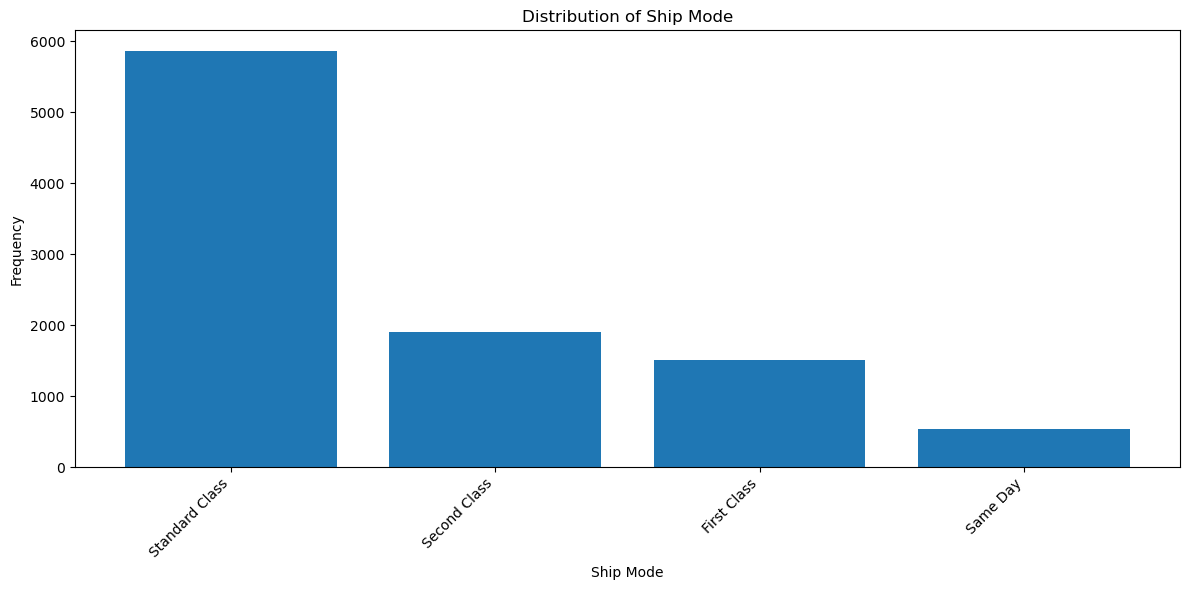

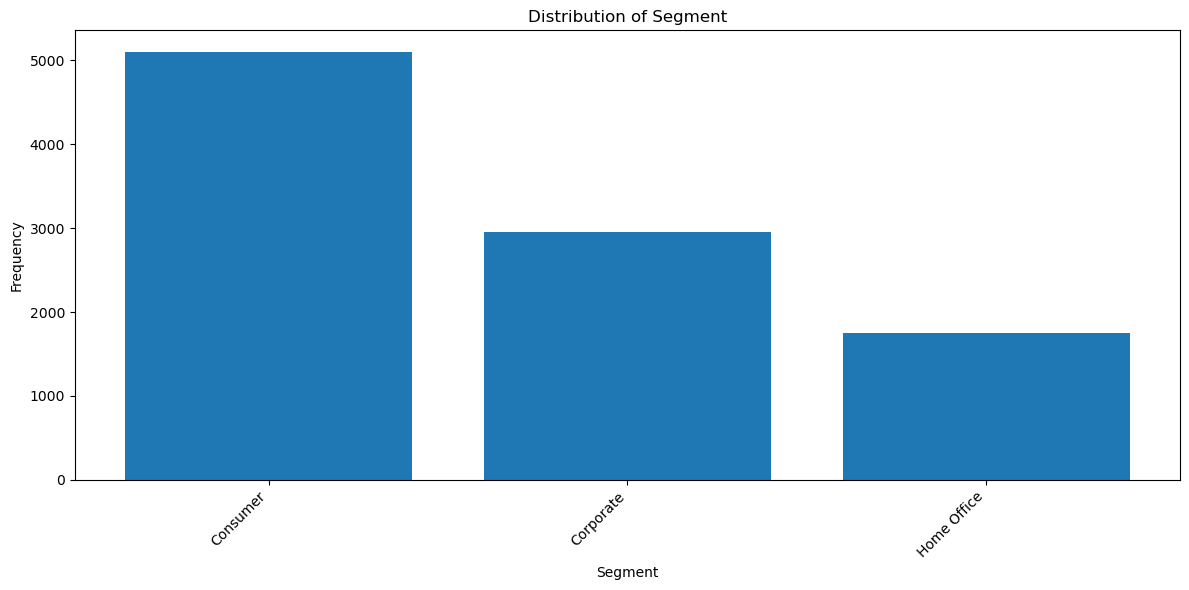

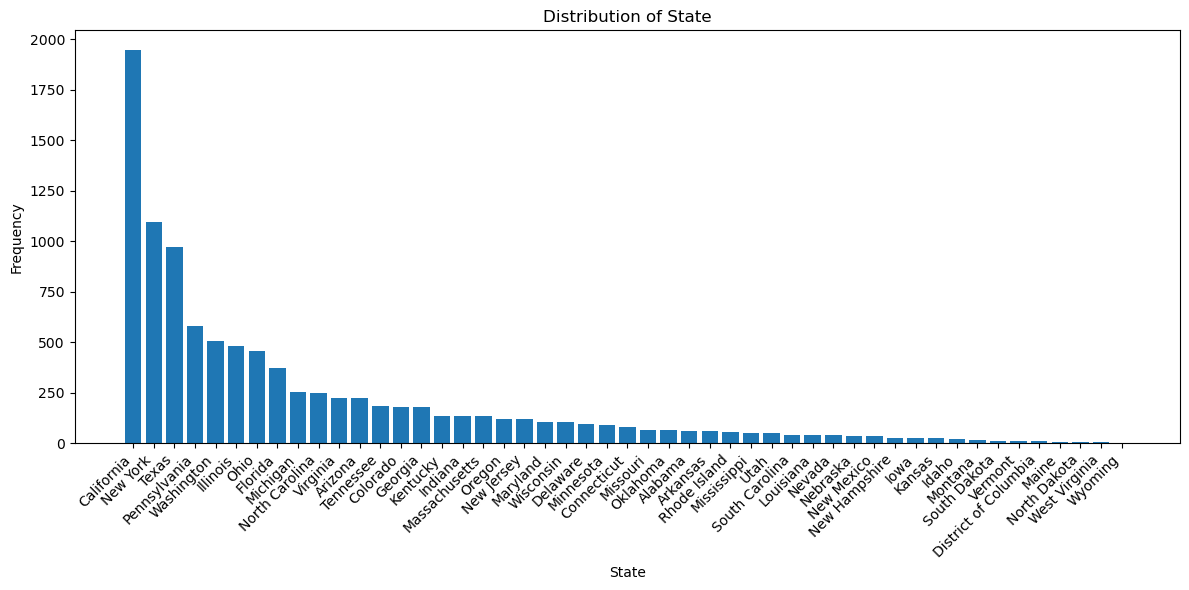

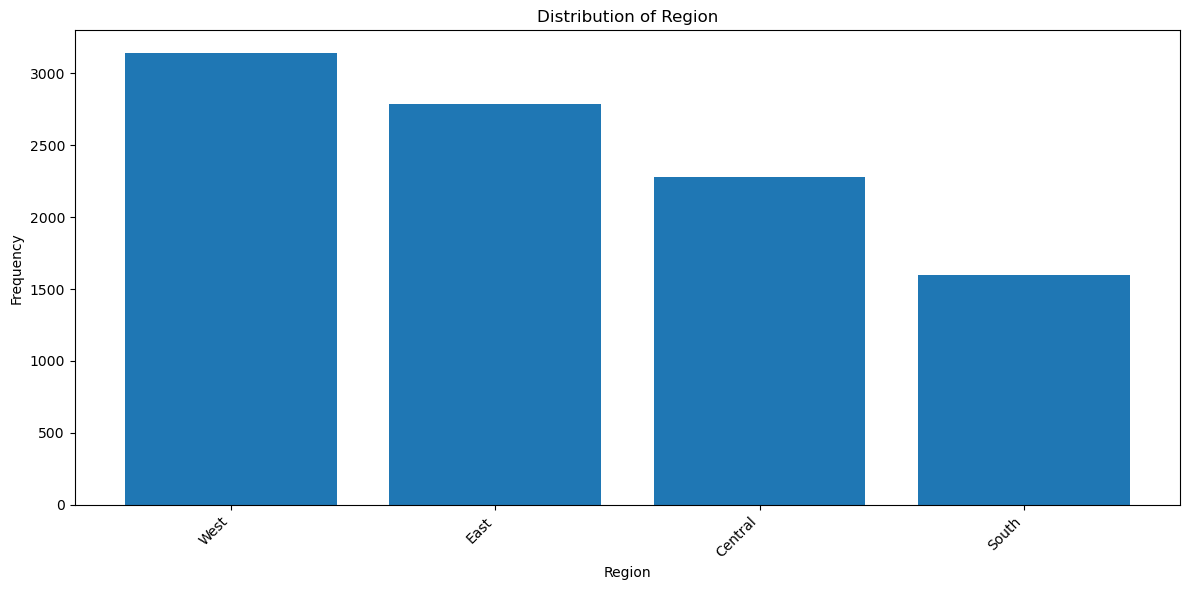

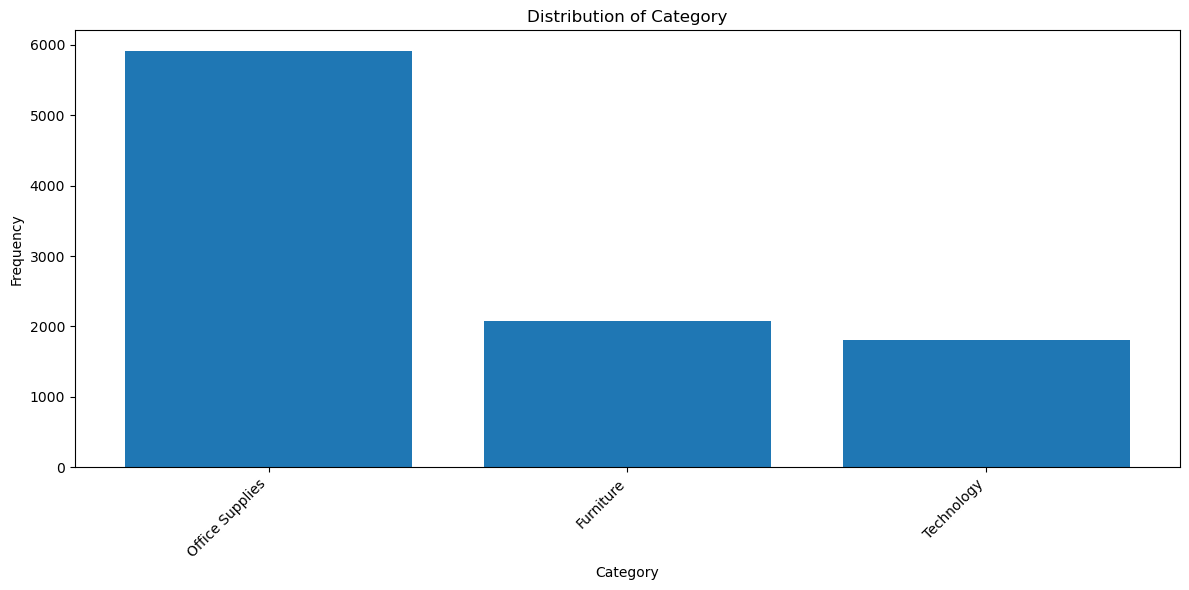

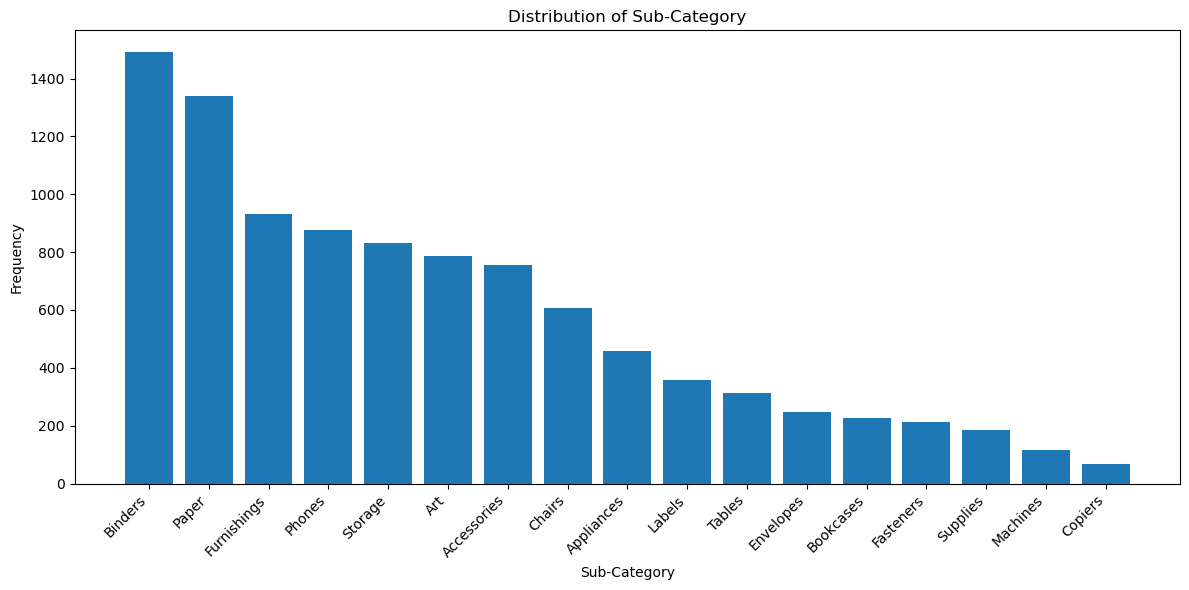

In [18]:
col=['Ship Mode','Segment','State','Region','Category','Sub-Category']

for i in col:
    plt.figure(figsize=(12, 6))

    counts = df[i].value_counts()
    plt.bar(counts.index, counts.values)

    plt.title(f'Distribution of {i}')
    plt.xlabel(i)
    plt.ylabel('Frequency')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


**observations:**
1. Ship Mode: Standard Class is the most frequently used shipping mode, while Same Day is the least frequent.

2. Segment: Consumer is the largest customer segment, followed by Corporate and Home Office.

3. State: California has the highest number of records, followed by New York and Texas. Wyoming has the lowest.

4. Region: West has the highest frequency, followed by East and Central. South has the lowest.

5. Category: Office Supplies is the most frequent category, followed by Furniture and Technology.

6. Sub-Category: Binders is the most frequent sub-category, followed by Paper. Copiers has the lowest frequency.

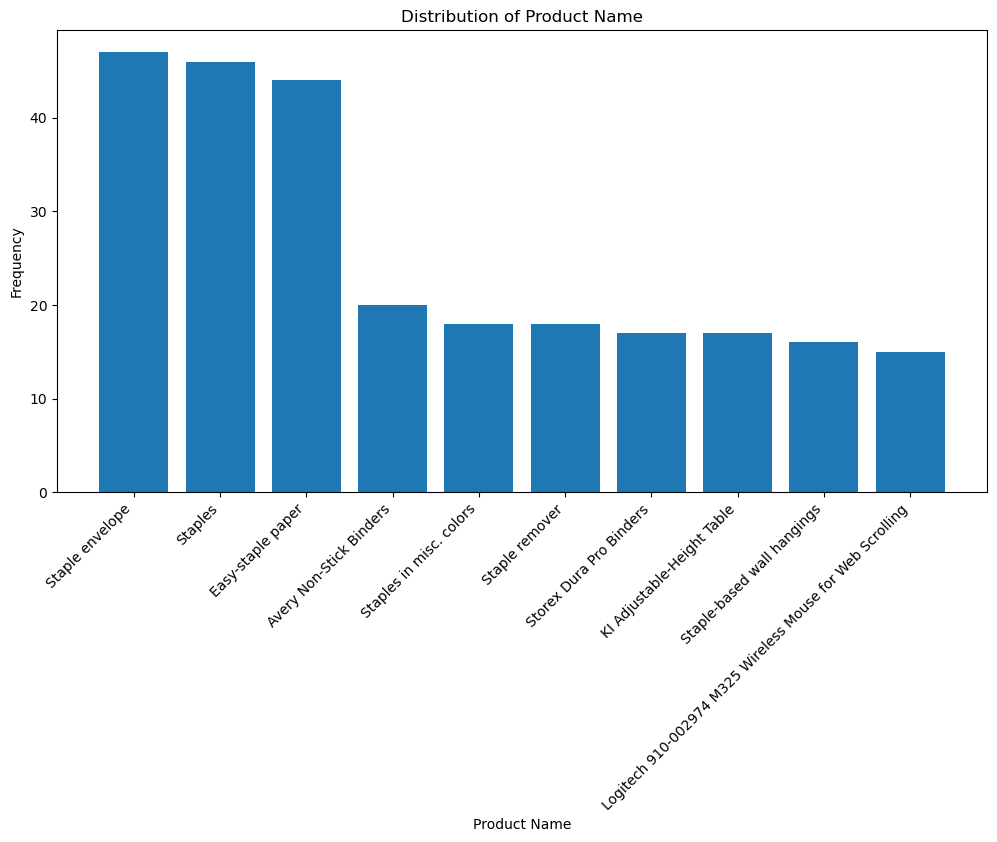

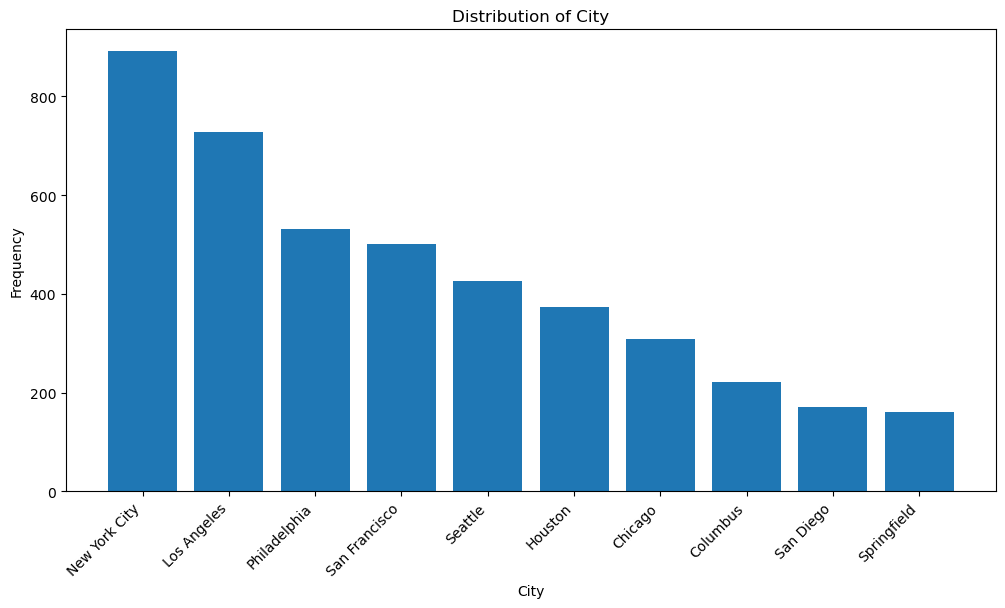

In [19]:
top_10_col=['Product Name', 'City']

for i in top_10_col:
    plt.figure(figsize=(12,6))
    counts=df[i].value_counts().head(10)
    plt.bar(counts.index, counts.values)

    plt.title(f'Distribution of {i}')
    plt.xlabel(i)
    plt.ylabel('Frequency')
    plt.xticks(rotation=45, ha='right')
    plt.show()

**observations:**
**Top 10 Product Names:**
- Staple Envelope is the most frequent product, followed by Staples and Easy-staple Paper.

**Top 10 Cities:**
- New York City has the highest frequency, followed by Los Angeles and Philadelphia.

**Skipped Columns:**
- Customer Name, Order ID, Product ID, and Customer ID were skipped due to many unique values.
- Country was skipped because it contains only one value: United States.

#### **#Numerical column analysis**

In [20]:
df[num_col].describe()

,Sales
count,9800.000000
mean,230.769059
std,626.651875
min,0.444000
25%,17.248000
50%,54.490000
75%,210.605000
max,22638.480000


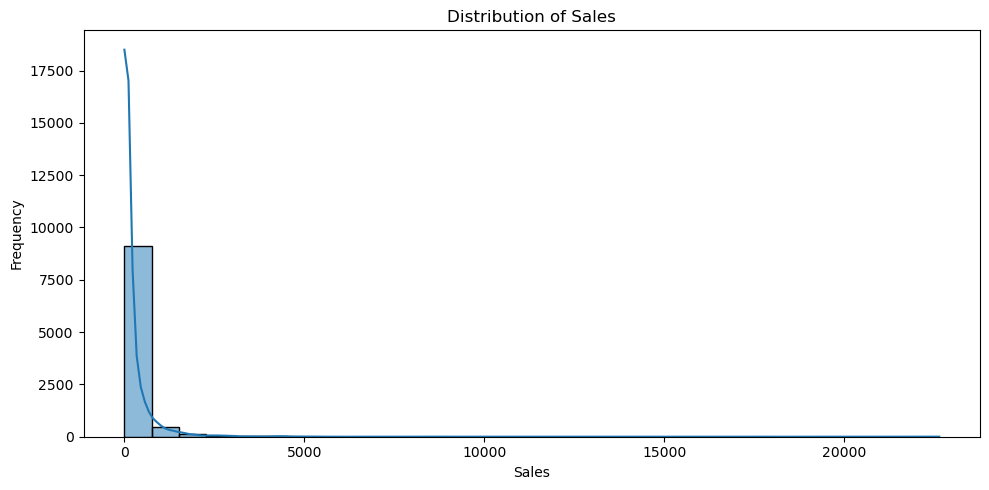

In [21]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Sales', bins=30, kde=True)

plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

**observation:**
- The Sales column is highly right-skewed (positively skewed).
- Most sales records have relatively low values.
- A small number of records have very high sales values, creating a long right tail.
- The distribution is not normally distributed.

#### 2. outlier analysis 

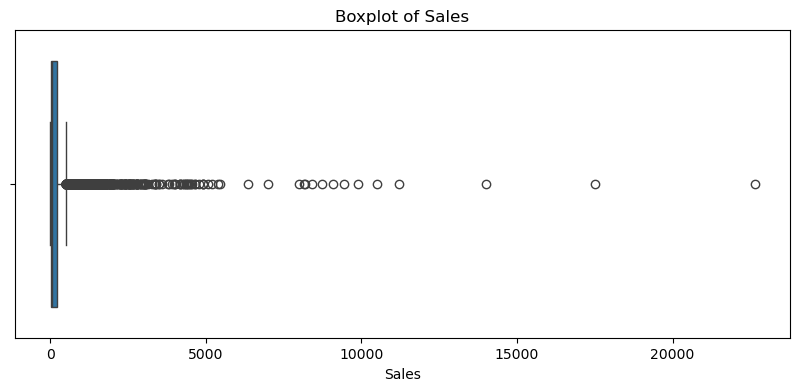

In [22]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['Sales'])
plt.title('Boxplot of Sales')
plt.show()

**Outlier Analysis — Sales**

- The boxplot shows many potential outliers above the upper whisker.
- Sales values are strongly right-skewed, with a few transactions having very high values.
- These outliers may represent genuine high-value transactions, so they should not be removed without further investigation.

In [23]:
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Sales'] < lower_limit) |
    (df['Sales'] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of outliers:", len(outliers))

Lower limit: -272.7875000000001
Upper limit: 500.6405000000001
Number of outliers: 1145


**Outlier Analysis — Sales**

- Lower limit: -272.79
- Upper limit: 500.64
- Number of potential outliers: 1,145
- Since sales values above 500.64 exceed the IQR upper limit, they are classified as potential outliers.
- These values may represent genuine high-value transactions, so they should not be removed automatically.

#### 3. Bivariate analysis 

**1) total sales by category**

**Q.Which product category generates the most sales?**

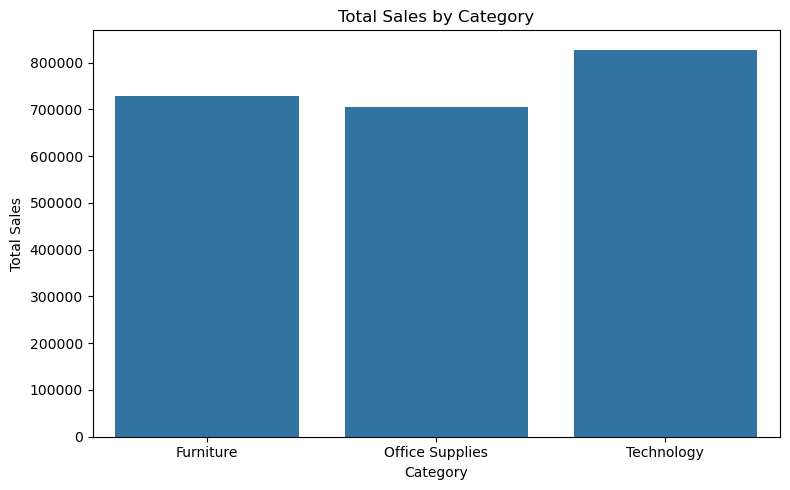

In [24]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Category', y='Sales', estimator='sum', errorbar=None)

plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

**observation:**
- Technology generates the highest total sales, at approximately 828,000.
- Furniture ranks second, with approximately 742,000 in sales.
- Office Supplies has the lowest total sales, at approximately 706,000.

**Conclusion:** Technology is the top-performing category in terms of total sales.

**2) total Sales by Region**

**Q. Which region generates the most sales?**

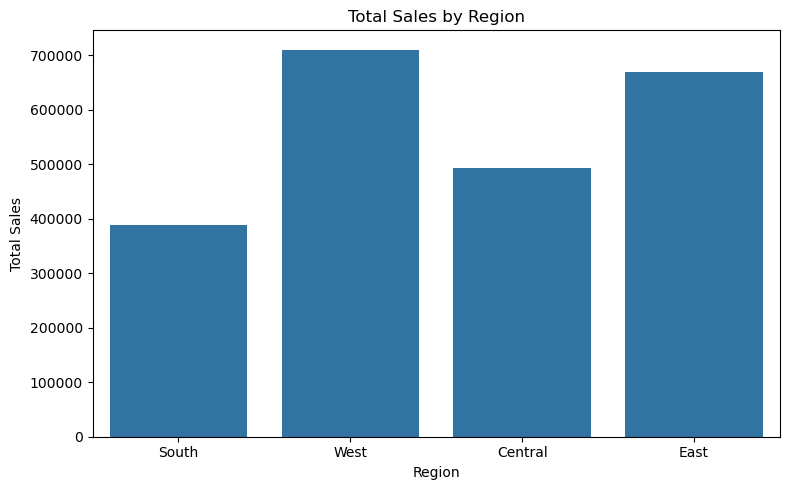

In [25]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Region',
    y='Sales',
    estimator='sum',
    errorbar=None
)

plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

**observations:**
- West region has the highest total sales, approximately 710,000.
- East ranks second, followed by Central.
- South has the lowest total sales, approximately 390,000.

**Conclusion:** The West region contributes the most to total sales, while the South contributes the least.

**3)Total Sales by Segment**

**Q. Which customer segment contributes the most sales?**

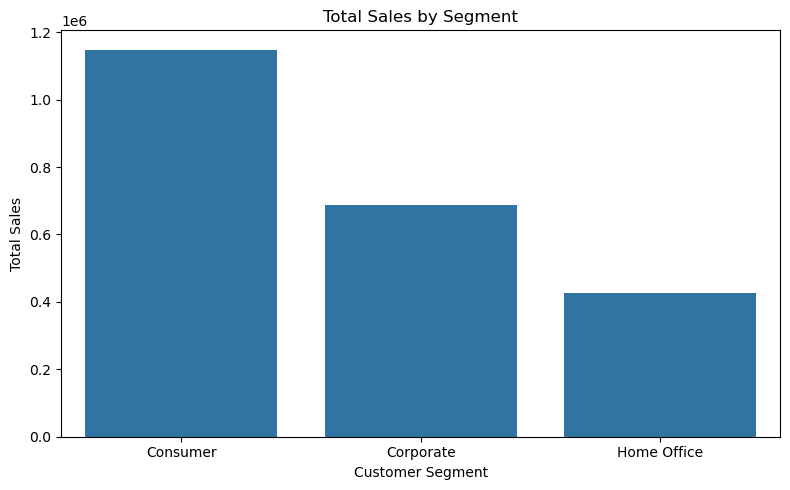

In [26]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Segment',
    y='Sales',
    estimator='sum',
    errorbar=None
)

plt.title('Total Sales by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

**observation:**
- Consumer segment generates the highest total sales, approximately 1.15 million.
- Corporate ranks second, with around 0.69 million.
- Home Office has the lowest total sales, approximately 0.42 million.
    
**Conclusion:** The Consumer segment contributes the most to total sales.

**4)Total Sales by Ship Mode**

**Q. How sales are distributed across shipping modes?**

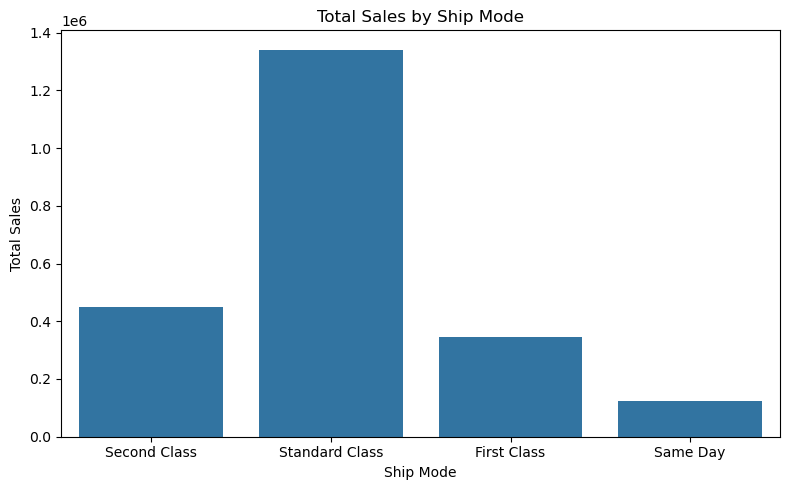

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Ship Mode',
    y='Sales',
    estimator='sum',
    errorbar=None
)

plt.title('Total Sales by Ship Mode')
plt.xlabel('Ship Mode')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

**observations:**
- Standard Class generates the highest total sales, approximately 1.34 million.
- Second Class ranks second, followed by First Class.
- Same Day generates the lowest total sales, approximately 0.13 million.
    
**Conclusion:** Standard Class contributes the most to total sales, while Same Day contributes the least.

**5) Total Sales by Sub-Category**

**Q.Which product sub-categories generate the most sales**

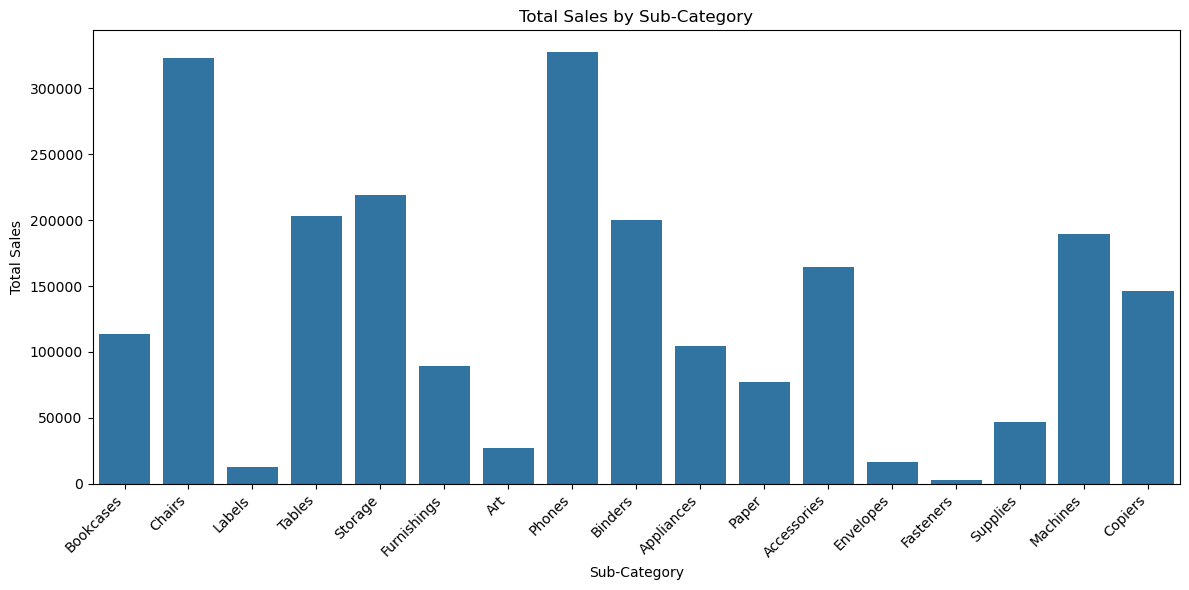

In [28]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x='Sub-Category',
    y='Sales',
    estimator='sum',
    errorbar=None
)

plt.title('Total Sales by Sub-Category')
plt.xlabel('Sub-Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**observations:**
- Phones and Chairs generate the highest total sales, at approximately 328,000 and 325,000, respectively.
- Storage, Tables, and Binders also contribute significantly to total sales.
- Fasteners has the lowest total sales, followed by Labels and Envelopes.

**Conclusion:** Phones and Chairs are the top-performing sub-categories by total sales, while Fasteners contributes the least.

**6) Total Sales by State**

**Q.Which states generate the most sales?**

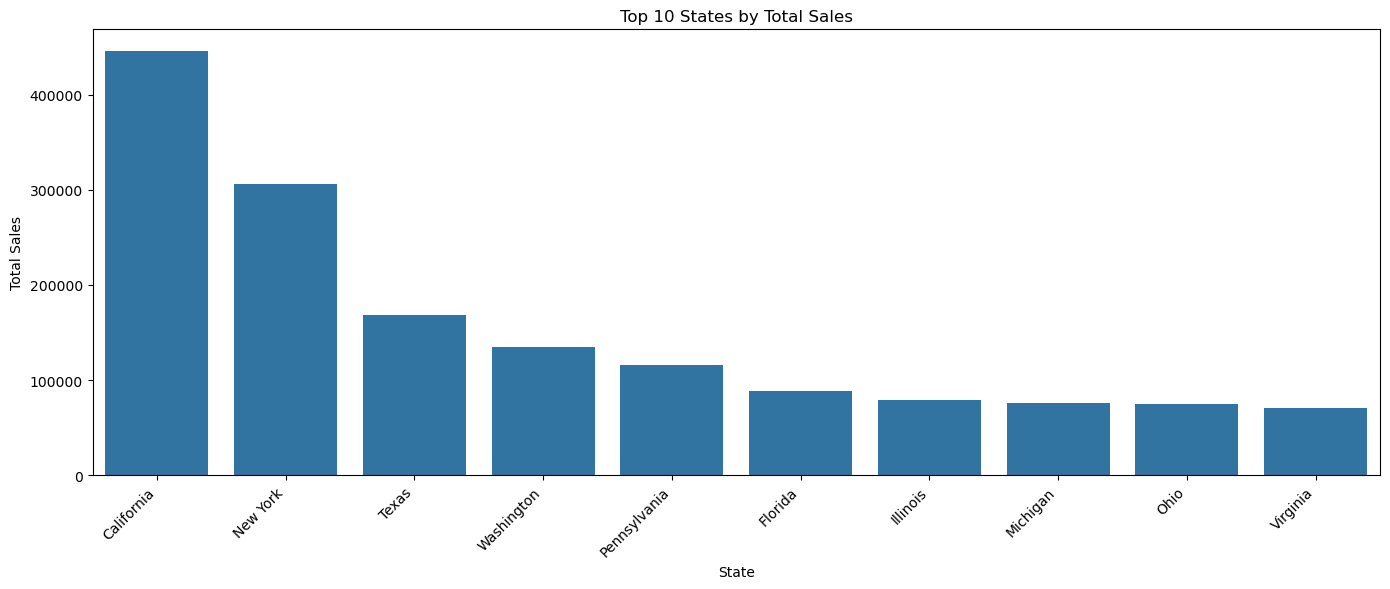

In [29]:
plt.figure(figsize=(14, 6))

state_sales = (
    df.groupby('State')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

sns.barplot(x=state_sales.index, y=state_sales.values)

plt.title('Top 10 States by Total Sales')
plt.xlabel('State')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**observations:**
- California has the highest total sales, approximately 450,000.
- New York ranks second, followed by Texas.
- Virginia has the lowest sales among the top 10 states, at approximately 70,000.

**Conclusion:** California is the leading state in terms of total sales.

**7) Top 10 Cities by Total Sales**

**Q. Which cities generate the most sales?**

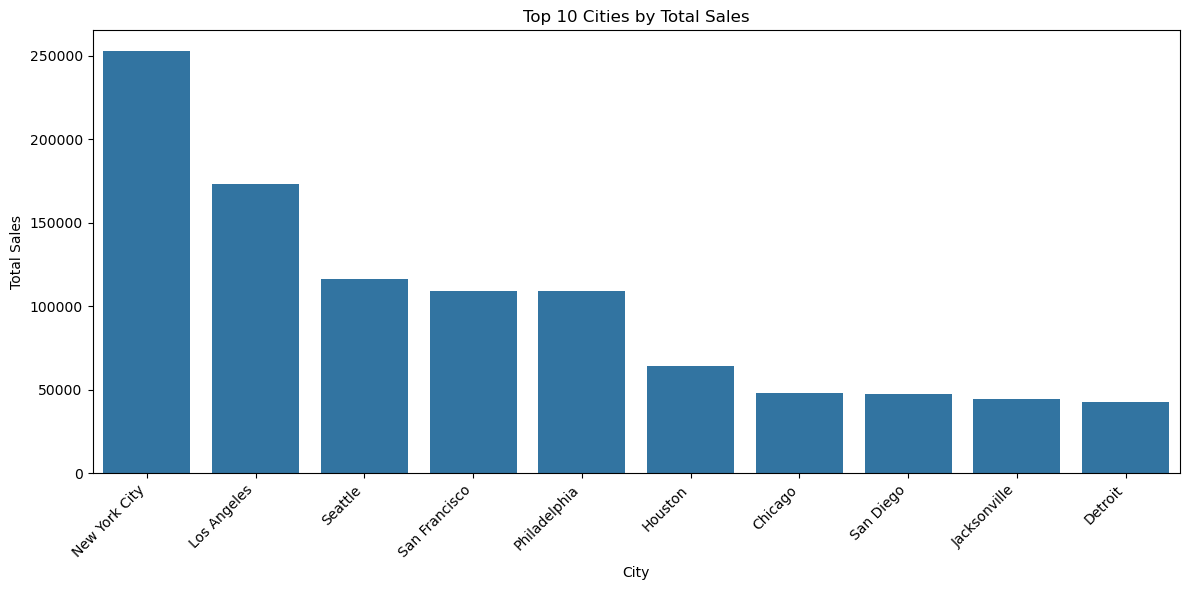

In [30]:
plt.figure(figsize=(12, 6))

city_sales = (
    df.groupby('City')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

sns.barplot(x=city_sales.index, y=city_sales.values)

plt.title('Top 10 Cities by Total Sales')
plt.xlabel('City')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**observation:**
- New York City has the highest total sales, approximately 252,000.
- Los Angeles ranks second, followed by Seattle.
- Detroit has the lowest total sales among the top 10 cities, at approximately 42,000.

**Conclusion:** New York City is the top-performing city in terms of total sales.

**8) Sales over time (Order Date)**

**Q. How sales change over time?**

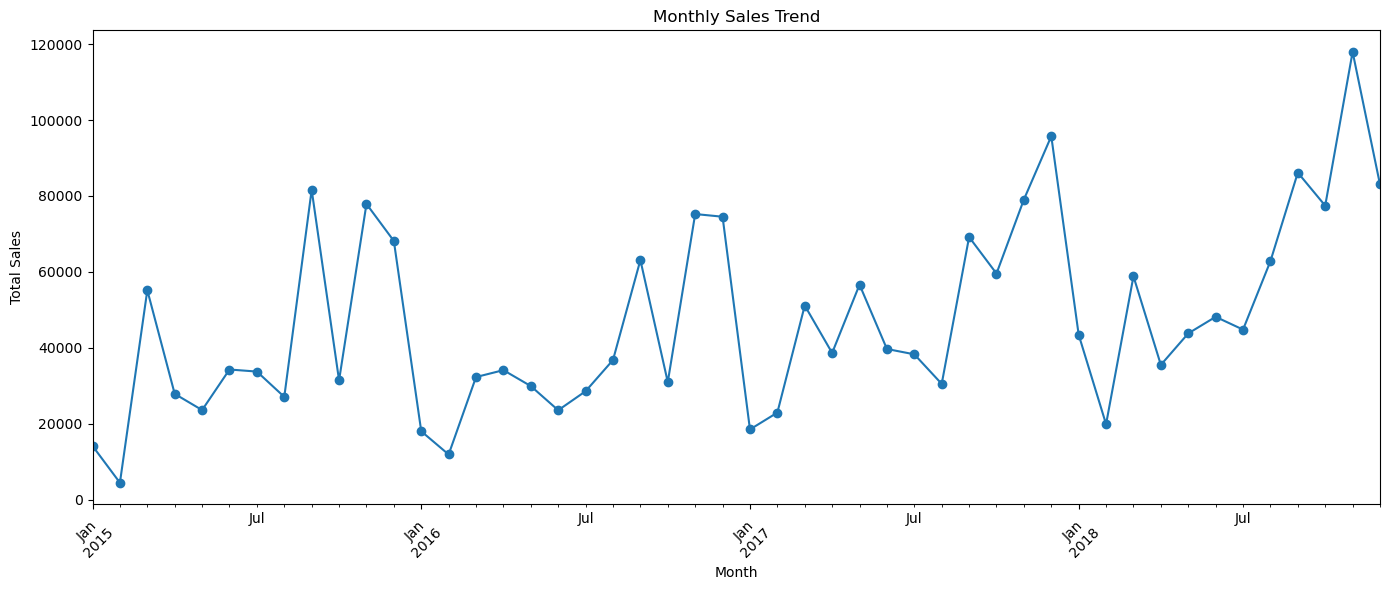

In [31]:
df['Order Month'] = df['Order Date'].dt.to_period('M')

monthly_sales = df.groupby('Order Month')['Sales'].sum()

plt.figure(figsize=(14, 6))
monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**observations:**
- Monthly sales fluctuate considerably throughout the period.
- Sales show an overall upward trend from 2015 to 2018.
- The highest monthly sales occur near the end of 2018, at approximately 118,000.
- Several months show sharp increases and decreases in sales.

**Conclusion:** Sales generally increased over time, but monthly performance was inconsistent.

#### 4.Multivariate analysis

**1. sales vs category vs region**

**Q. Which product category performs best in each region?**

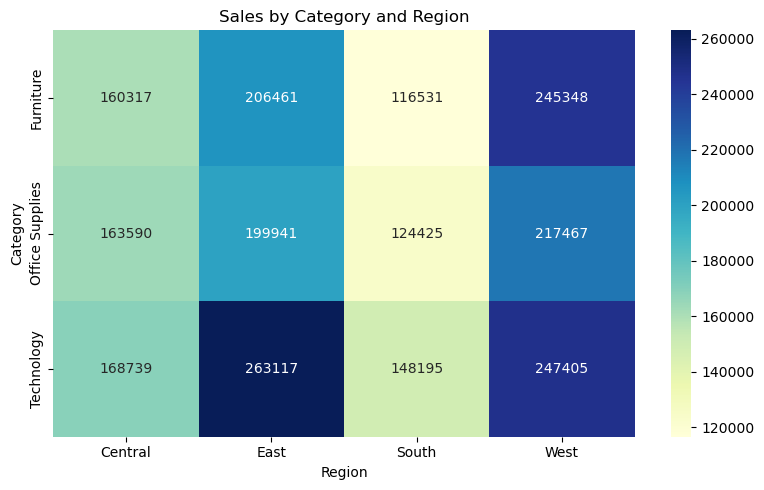

In [32]:
pivot_sales = df.pivot_table(
    values='Sales',
    index='Category',
    columns='Region',
    aggfunc='sum'
)

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_sales, annot=True, fmt='.0f', cmap='YlGnBu')

plt.title('Sales by Category and Region')
plt.tight_layout()
plt.show()

**OBSERVATIONS:**
- Technology generates the highest sales in the East region (263,317).
- Furniture generates the highest sales in the West region (245,348).
- Technology performs strongly in both the East and West regions.
- South has the lowest sales across all three categories compared with the other regions.

**Conclusion:** Sales performance varies by category and region. Technology leads in the East, while Furniture performs best in the West.

**2.Sales by Customer Segment and Category**

**Q.Which product category generates the highest sales for each customer segment, and does the Consumer segment lead across all categories?**

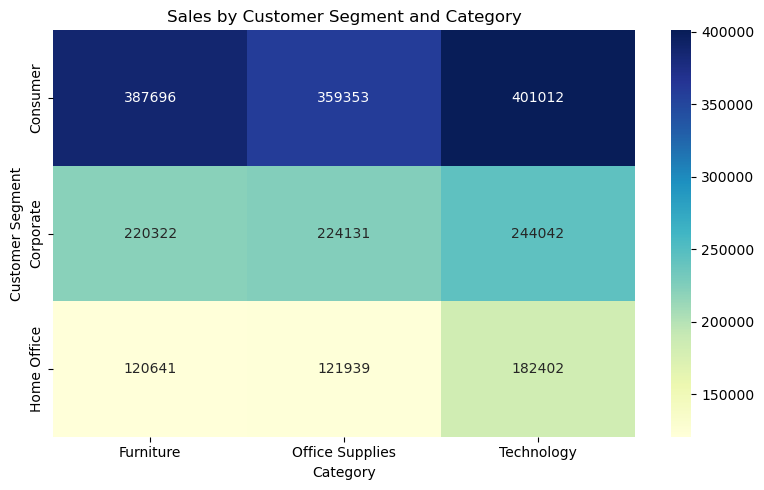

In [33]:
pivot_segment = df.pivot_table(
    values='Sales',
    index='Segment',
    columns='Category',
    aggfunc='sum'
)

plt.figure(figsize=(8, 5))
sns.heatmap(
    pivot_segment,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title('Sales by Customer Segment and Category')
plt.xlabel('Category')
plt.ylabel('Customer Segment')
plt.tight_layout()
plt.show()

**observations:**
- Consumer generates the highest sales in Technology (401,012), followed by Furniture and Office Supplies.
- Corporate generates the highest sales in Technology (244,042).
- Home Office also generates the highest sales in Technology (182,402).
- The Consumer segment contributes the most sales across all three categories.

**Conclusion:** Technology is the top-selling category for all three customer segments, and Consumer contributes the highest sales overall.

**3. Sales by sub-category and region** 

**Q. Which sub-categories generate the highest sales in each region?**

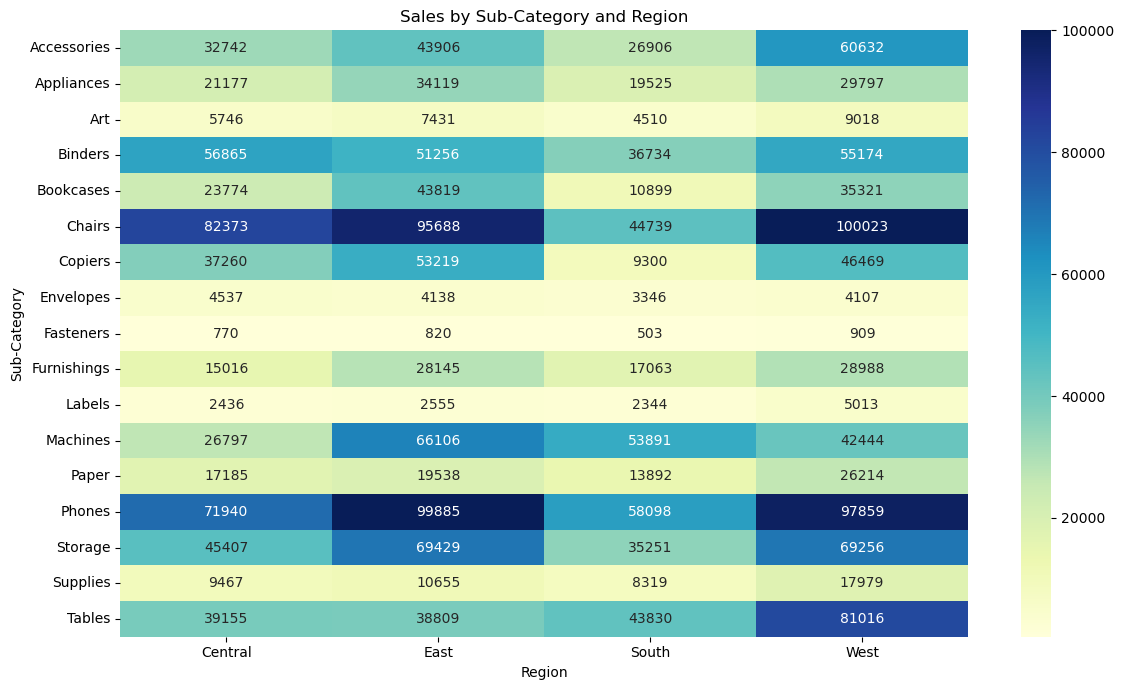

In [34]:
pivot_sub = df.pivot_table(
    values='Sales',
    index='Sub-Category',
    columns='Region',
    aggfunc='sum'
)

plt.figure(figsize=(12, 7))
sns.heatmap(pivot_sub, annot=True, fmt='.0f', cmap='YlGnBu')

plt.title('Sales by Sub-Category and Region')
plt.xlabel('Region')
plt.ylabel('Sub-Category')
plt.tight_layout()
plt.show()

**observations:**
- Chairs generate the highest sales in Central, East, and West among the displayed sub-categories.
- Phones also perform strongly, especially in the East (99,885) and West (97,859).
- Machines perform best in the South (53,891).
- Fasteners have the lowest sales across all four regions.

**Conclusion:** Chairs and Phones are strong-performing sub-categories across regions, while Machines lead in the South. Fasteners consistently generate the lowest sales.

**4.Monthly sales trend by category**

**Q. How do monthly sales trends differ across product categories?**

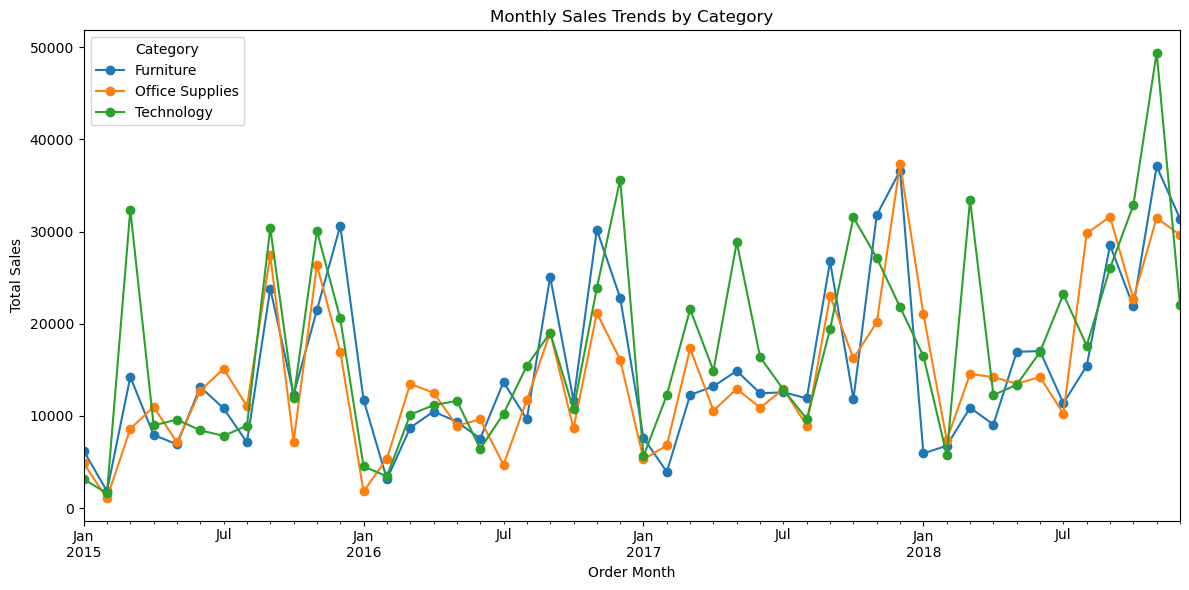

In [35]:
df['Order Month'] = df['Order Date'].dt.to_period('M').dt.to_timestamp()

monthly_category_sales = df.pivot_table(
    values='Sales',
    index='Order Month',
    columns='Category',
    aggfunc='sum'
)

monthly_category_sales.plot(figsize=(12, 6), marker='o')

plt.title('Monthly Sales Trends by Category')
plt.xlabel('Order Month')
plt.ylabel('Total Sales')
plt.legend(title='Category')
plt.tight_layout()
plt.show()

**observations:**
- Sales fluctuate considerably across all three categories from 2015 to 2018.
- Technology shows several strong sales peaks, including the highest peak near the end of 2018.
- Furniture and Office Supplies also show periodic increases and decreases in monthly sales.
- Overall, sales activity appears stronger toward the end of the period, although monthly performance remains inconsistent.

**Conclusion:** Technology shows some of the strongest monthly sales peaks, but all three categories experience fluctuations over time.

#### 5. Time-Series Analysis

**1.Analyze yearly sales growth**

**Q. How have total sales changed each year from 2015 to 2018?**

Order Date
2015    479856.2081
2016    459436.0054
2017    600192.5500
2018    722052.0192
Name: Sales, dtype: float64


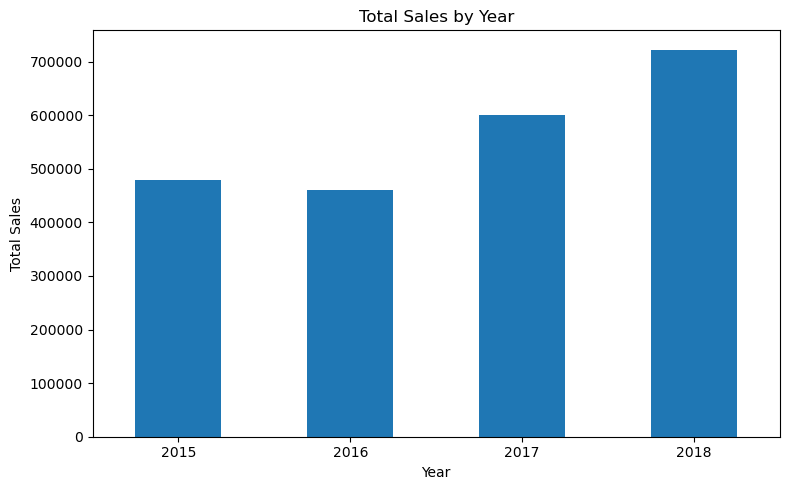

In [36]:
yearly_sales = df.groupby(
    df['Order Date'].dt.year
)['Sales'].sum()

print(yearly_sales)

yearly_sales.plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Sales by Year'
)

plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [37]:
# Calculating year-over-year growth
yearly_growth = yearly_sales.pct_change() * 100

print("Year-over-Year Sales Growth (%):")
print(yearly_growth.round(2))

Year-over-Year Sales Growth (%):
Order Date
2015      NaN
2016    -4.26
2017    30.64
2018    20.30
Name: Sales, dtype: float64


**observations:**
- Total sales decreased by 4.26% in 2016 compared with 2015.
- Sales increased by 30.64% in 2017, showing strong growth.
- Sales increased by another 20.30% in 2018.
- 2018 recorded the highest total sales, at approximately 722,052.
    
**Conclusion:** Despite a decline in 2016, sales recovered strongly in 2017 and continued growing in 2018.

**2.Analyze monthly sales seasonality**

**Q. Which months generate the highest and lowest total sales across all years?**

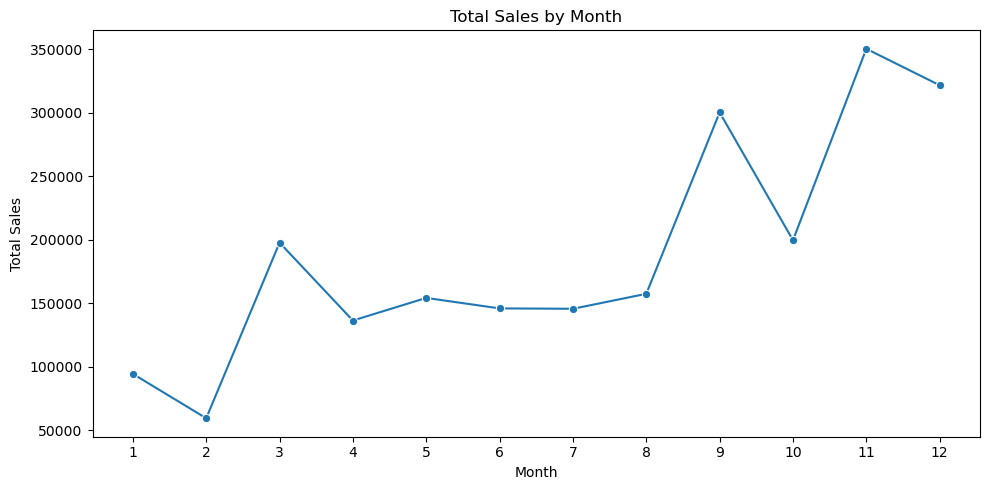

Order Date
11    350161.7110
12    321480.1695
9     300103.4117
10    199496.2947
3     197573.5872
8     157315.9270
5     154086.7237
6     145837.5233
7     145535.6890
4     136283.0006
1      94291.6296
2      59371.1154
Name: Sales, dtype: float64


In [38]:
monthly_sales = df.groupby(
    df['Order Date'].dt.month
)['Sales'].sum()

plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker='o')

plt.title('Total Sales by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

print(monthly_sales.sort_values(ascending=False))

**observations:**
- November has the highest total sales, approximately 350,162.
- December ranks second, followed by September.
- February has the lowest total sales, approximately 59,371.
- Sales increase considerably during the final months of the year, particularly in November and December.

**Conclusion:** November is the strongest month for total sales, while February is the weakest.

### save cleaned data 

In [39]:
df.to_csv('superstore_cleaned.csv', index=False)